# 4-Way Model Comparison: Raw NWP vs. Traditional AnEn vs. Deep-AnEn-Regression vs. Deep Analog (Hu et al., 2023)

**Phase 4 — Hu et al. (2023) Deep Analog benchmark + unified comparison**
Repository: [Mahinul372/ML-Analog-Ensemble-Severe-Weather](https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather)

Phase 3 showed the classical Traditional AnEn narrowly beating the
regression-trained Deep-AnEn-Regression. Phase 4 asks whether the
*paper-based* Deep Analog — Hu et al.'s LSTM trained with Reverse Analog
triplet learning — does better than either. This notebook answers that
with the same strict apples-to-apples benchmark:

| Method | Search space | K |
|---|---|---|
| **Raw NWP** | — (deterministic `fcst_gust`) | — |
| **Traditional AnEn** | 4-D standardized forecast space, Euclidean | 15 |
| **Deep-AnEn-Regression** (Phase 2) | 16-D regression-trained latent embedding, Euclidean | 15 |
| **Deep Analog (Hu et al., 2023)** (Phase 4) | 20-D LSTM triplet embedding, Euclidean | 15 |

**The scientific guarantee:** all four methods are evaluated on the
**exact same 130 untouched test storm events** (observed gust ≥ 35 km/h,
2026-09-01 → 2026-11-01). The timestamp list is built **once** in
`data_prep.get_storm_events()` and shared by every method — never
re-derived per method — and the notebook asserts all four methods
evaluated identical timestamps. Splits, scaler, and episode selection
likewise come from the single shared protocol in `data_prep.py`.
Deep-AnEn-Regression and Deep Analog (Hu et al., 2023) numbers are **recomputed
here from their saved weights** (never retrained here, never copied from
earlier phases) — and checked against the saved metric files for
consistency.

**How to run:** open in Google Colab → *Runtime → Change runtime type →
GPU (T4)* → *Runtime → Run all*.

**Long-archive extension (§5–§8).** The same four methods are then
re-benchmarked on a long archive (2018-01-01 → 2026-11-01, 77,448
hourly rows; train 59,928 / val 8,760 / test 8,760; **1,286** test storm
events), with Diebold-Mariano significance tests for both regimes (§6),
the dual-regime comparison table, and the training-vs-validation loss
curves for both neural models in both regimes (§7, overfitting check).
The long archive starts 2018-01-01 because the Open-Meteo Previous-Runs
API returns no valid forecasts earlier (verified by probe).

In [1]:
# --- Setup: device, dependencies, repo location -------------------------------
import warnings
warnings.filterwarnings("ignore")

import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "properscoring"])

import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import properscoring

torch.manual_seed(42)
np.random.seed(42)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} | device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# Locate the repo root (same logic as the Phase 2 notebook).
if os.path.exists("data/atlanta_weather_archive.csv"):
    pass
elif os.path.exists("../data/atlanta_weather_archive.csv"):
    os.chdir("..")
else:
    print("Cloning repository ...")
    os.system("git clone -q https://github.com/Mahinul372/ML-Analog-Ensemble-Severe-Weather.git")
    os.chdir("ML-Analog-Ensemble-Severe-Weather")
print("Working directory:", os.getcwd())
os.makedirs("plots", exist_ok=True)
os.makedirs("metrics", exist_ok=True)

# Shared protocol: one canonical split, scaler, storm-event list, episode.
sys.path.insert(0, os.getcwd())
from data_prep import (
    EXCLUSION_HOURS,
    FEATURES,
    K,
    TARGET,
    TRAIN_END,
    fit_feature_scaler,
    get_severe_episode,
    get_storm_events,
    load_and_split,
    load_archive,
    split_archive,
)
from traditional_anen import TraditionalAnalogEnsemble
from phase4_triplet import (
    SequenceStore,
    embed_positions,
    load_triplet_model,
    retrieve_analogs,
)
from dm_tests import diebold_mariano, run_dm_for_regime

PyTorch 2.15.0+cpu | device: cpu
Working directory: /home/hatch/workspace/ml-analog-ensemble-severe-weather


## 1. Shared Experimental Protocol (`data_prep.py`)

Everything below is defined **once** in `data_prep.py` and imported by
every experiment — preprocessing and splits are never recreated per
method:

- **Dataset:** `data/atlanta_weather_archive.csv` — 8,760 hourly rows,
  Atlanta, GA, 2025-11-02 → 2026-11-01 (UTC).
- **Predictors:** the same 4 standardized forecast variables
  (`fcst_temp`, `fcst_wind`, `fcst_gust`, `fcst_press`).
- **Splits (strictly chronological):** train ≤ 2026-08-15, validation to
  2026-08-31, test from 2026-09-01. The `StandardScaler` is fit on the
  **training split only**.
- **Evaluation subset, defined once:** every test-window hour with
  observed gust ≥ 35 km/h — **130 timestamps**. All four methods loop
  over this exact list.
- **Leakage control:** ±7-day exclusion window around each target; analogs
  drawn only from the **training archive**.
- **Ensemble size:** K = 15 members for all three analog methods.
- **Scores:** deterministic RMSE of the ensemble mean; probabilistic
  CRPS (`properscoring.crps_ensemble`) over the 15 members. For the
  deterministic Raw NWP forecast, CRPS is the **mean absolute error** —
  the exact single-member equivalent of ensemble CRPS.
- **90% bands are prediction intervals** (5th–95th percentile of the
  15 ensemble members), not confidence intervals: they describe the
  spread of the predictive distribution, not uncertainty about a
  parameter. Note that 15 members give **coarse** percentile estimates —
  each member spans ~1/15 (≈6.7%) of the probability mass, so p5/p95 sit
  near the 1st and 15th order statistics.
- **Phase 4 model:** Hu et al. (2023) Deep Analog — 3-layer LSTM
  (20 hidden, dropout 0.01) + linear layer to 20-D embeddings, trained
  with TripletMarginLoss (margin 0.9, the official default) on Reverse
  Analog triplets sampled fitness-proportionately from training data
  only. Input is a 24 h lookback window of hourly forecasts (adaptation:
  the paper's sequence is a lead-time window; see `phase4_triplet.py`).
  No regression head, no L2 normalization — verified against the official
  implementation at https://github.com/uga-gaim/DeepAnalog.

In [2]:
# --- Load data and all engines from the SHARED protocol ------------------------
df = load_archive()
train_df, val_df, test_df = split_archive(df)
print(f"Archive: {len(df)} hourly rows, {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test window: {len(test_df)} rows")

# The evaluation subset, defined ONCE and shared by all four methods.
storms = get_storm_events(test_df)
EVENT_TIMESTAMPS = list(storms["timestamp"])
print(f"Test storm events (obs_gust >= 35 km/h): {len(EVENT_TIMESTAMPS)}")
print(f"First: {EVENT_TIMESTAMPS[0]} | Last: {EVENT_TIMESTAMPS[-1]}")

# Scaler from the shared protocol (fit on train only — same in all phases).
feat_scaler = fit_feature_scaler(train_df)

# Traditional AnEn: direct 4-D Euclidean search (no neural network).
trad = TraditionalAnalogEnsemble(df)

# --- Deep-AnEn-Regression: rebuild the Phase 2 encoder from saved weights ---
class DeepAnalogRegressionEncoder(nn.Module):
    """Forecast (4) -> 32 -> ReLU -> Dropout -> 16-D latent embedding."""

    def __init__(self, input_dim=4, hidden_dim=32, latent_dim=16, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, latent_dim),
        )
        self.head = nn.Linear(latent_dim, 1)

    def encode(self, x):
        return self.net(x)

    def forward(self, x):
        return self.head(self.encode(x))


ckpt = torch.load("models/deep_anen_regression_weights.pth", map_location=DEVICE,
                  weights_only=True)
encoder = DeepAnalogRegressionEncoder().to(DEVICE)
encoder.load_state_dict(ckpt["encoder_state_dict"])
encoder.eval()
print(f"Loaded Deep-AnEn-Regression weights (trained {ckpt['config']['epochs']} epochs, "
      f"K={ckpt['config']['K']})")

X_train = torch.tensor(feat_scaler.transform(train_df[FEATURES]),
                       dtype=torch.float32).to(DEVICE)
with torch.no_grad():
    train_z = encoder.encode(X_train).cpu().numpy()  # (n_train, 16)
print(f"Latent training archive: {train_z.shape}")


def regression_find_analogs(target_timestamp, K=K):
    """K nearest training-period analogs in the 16-D latent space.

    Returns a dict with the same shape as TraditionalAnalogEnsemble
    .find_analogs(): the 15-member observed-gust ensemble plus the analog
    timestamps and distances (needed by the verification audit).
    """
    target = pd.to_datetime(target_timestamp, utc=True)
    row = df[df["timestamp"] == target]
    x = torch.tensor(feat_scaler.transform(row[FEATURES]),
                     dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        z = encoder.encode(x).cpu().numpy()[0]
    delta_h = (train_df["timestamp"] - target).dt.total_seconds() / 3600.0
    cand_idx = np.where((delta_h.abs() > EXCLUSION_HOURS).values)[0]
    dists = np.linalg.norm(train_z[cand_idx] - z, axis=1)
    order = np.argsort(dists)[:K]
    analog_idx = cand_idx[order]
    members = train_df.loc[analog_idx, TARGET].to_numpy(dtype=float)
    return {
        "target_timestamp": str(target),
        "ensemble_members": members,
        "analogs": [
            {"timestamp": str(train_df.loc[i, "timestamp"]), "distance": float(d)}
            for i, d in zip(analog_idx, dists[order])
        ],
    }

# --- Deep Analog (Hu et al., 2023): load the Phase 4 triplet checkpoint ---------------
triplet_model, triplet_ckpt = load_triplet_model(
    "models/deep_anen_triplet_weights.pth", DEVICE)
print(f"Loaded Deep Analog (Hu et al., 2023) weights (best epoch "
      f"{triplet_ckpt['history']['best_epoch']}, "
      f"val loss {triplet_ckpt['history']['best_val_loss']:.4f})")
triplet_store = SequenceStore(df, feat_scaler)
triplet_train_pos = triplet_store.eligible_positions(train_df)
triplet_train_emb = embed_positions(triplet_model, triplet_store,
                                    triplet_train_pos, DEVICE)
print(f"Triplet training archive embeddings: {triplet_train_emb.shape}")


def triplet_find_analogs(target_timestamp, K=K):
    """K nearest training analogs in the 20-D LSTM triplet embedding space.

    Same return shape as the other find_analogs helpers (ensemble members
    plus analog timestamps/distances) so the audit can treat all three
    analog methods identically.
    """
    members, analog_pos, dists = retrieve_analogs(
        triplet_model, triplet_store, triplet_train_pos, [target_timestamp],
        DEVICE, k=K, train_emb=triplet_train_emb)
    return {
        "target_timestamp": str(pd.to_datetime(target_timestamp, utc=True)),
        "ensemble_members": members[0],
        "analogs": [
            {"timestamp": str(df.loc[p, "timestamp"]), "distance": float(d)}
            for p, d in zip(analog_pos[0], dists[0])
        ],
    }

Archive: 8760 hourly rows, 2025-11-02 00:00:00+00:00 → 2026-11-01 23:00:00+00:00
Train: 6888 | Val: 384 | Test window: 1488 rows
Test storm events (obs_gust >= 35 km/h): 130
First: 2026-09-06 22:00:00+00:00 | Last: 2026-11-01 23:00:00+00:00
Loaded Deep-AnEn-Regression weights (trained 30 epochs, K=15)


Latent training archive: (6888, 16)
Loaded Deep Analog (Hu et al., 2023) weights (best epoch 95, val loss 0.6168)


Triplet training archive embeddings: (6865, 20)


## 2. The Four Methods on the Identical Test Set

For each of the 130 shared storm-event timestamps we collect:

1. **Raw NWP** — the deterministic forecast `fcst_gust` (no ensemble).
2. **Traditional AnEn** — 15-member ensemble from direct Euclidean search
   in the 4-D standardized forecast space.
3. **Deep-AnEn-Regression** — 15-member ensemble from Euclidean search in
   the learned 16-D latent space (Phase 2 weights reloaded above, never
   retrained here).
4. **Deep Analog (Hu et al., 2023)** — 15-member ensemble from Euclidean search in
   the learned 20-D LSTM triplet embedding space (Phase 4 weights reloaded
   above, never retrained here).

RMSE is computed on the ensemble mean; CRPS on the full 15-member
ensemble for all three analog methods, and as mean absolute error for
Raw NWP. The three saved metric files
(`metrics/deep_anen_regression_metrics.json`,
`metrics/traditional_anen_metrics.json`,
`metrics/deep_anen_triplet_metrics.json`) are re-checked against the
recomputed numbers — any mismatch would mean the test set or protocol
drifted between phases.

In [3]:
# --- Evaluate all four methods on the IDENTICAL 130 timestamps -------------
# Every method iterates over the SAME pre-defined EVENT_TIMESTAMPS list.
raw_fcst, obs = [], []
trad_members, regression_members, triplet_members = [], [], []
evaluated_ts = []
for ts in EVENT_TIMESTAMPS:
    row = test_df[test_df["timestamp"] == ts].iloc[0]
    raw_fcst.append(row["fcst_gust"])
    obs.append(row[TARGET])
    trad_members.append(trad.find_analogs(ts, K=K)["ensemble_members"])
    regression_members.append(regression_find_analogs(ts, K=K)["ensemble_members"])
    triplet_members.append(triplet_find_analogs(ts, K=K)["ensemble_members"])
    evaluated_ts.append(ts)

# Guard: all four methods evaluated the exact same 130 timestamps.
assert evaluated_ts == EVENT_TIMESTAMPS and len(evaluated_ts) == 130
assert len(raw_fcst) == len(obs) == len(trad_members) == len(regression_members) == len(triplet_members) == 130

raw_fcst = np.array(raw_fcst)
obs = np.array(obs)
trad_members = np.array(trad_members)              # (130, 15)
regression_members = np.array(regression_members)  # (130, 15)
triplet_members = np.array(triplet_members)        # (130, 15)
trad_mean = trad_members.mean(axis=1)
regression_mean = regression_members.mean(axis=1)
triplet_mean = triplet_members.mean(axis=1)

rmse = lambda a, b: float(np.sqrt(np.mean((a - b) ** 2)))
crps_ens = lambda o, f: float(np.mean(properscoring.crps_ensemble(o, f)))

scores = {
    # Raw NWP is deterministic: CRPS = mean absolute error (single-member CRPS).
    "Raw NWP": (rmse(raw_fcst, obs), float(np.mean(np.abs(raw_fcst - obs)))),
    "Traditional AnEn": (rmse(trad_mean, obs), crps_ens(obs, trad_members)),
    "Deep-AnEn-Regression": (rmse(regression_mean, obs), crps_ens(obs, regression_members)),
    "Deep Analog (Hu et al., 2023)": (rmse(triplet_mean, obs), crps_ens(obs, triplet_members)),
}

summary = pd.DataFrame(
    {"Method": list(scores.keys()),
     "RMSE": [v[0] for v in scores.values()],
     "CRPS": [v[1] for v in scores.values()]},
)
display(summary.round(2))
print(f"\nBest RMSE: {min(scores, key=lambda m: scores[m][0])} "
      f"({min(v[0] for v in scores.values()):.2f} km/h)")
print(f"Best CRPS: {min(scores, key=lambda m: scores[m][1])} "
      f"({min(v[1] for v in scores.values()):.2f} km/h)")

# --- Consistency check against the saved Phase 2 / 3 / 4 metrics ------------
saved_regression = json.load(open("metrics/deep_anen_regression_metrics.json"))
saved_trad = json.load(open("metrics/traditional_anen_metrics.json"))
saved_triplet = json.load(open("metrics/deep_anen_triplet_metrics.json"))
assert abs(scores["Deep-AnEn-Regression"][0] - saved_regression["rmse_deep_anen_regression_kmh"]) < 0.05, \
    "Deep-AnEn-Regression RMSE does not reproduce Phase 2!"
assert abs(scores["Deep-AnEn-Regression"][1] - saved_regression["crps_deep_anen_regression_kmh"]) < 0.05, \
    "Deep-AnEn-Regression CRPS does not reproduce Phase 2!"
assert abs(scores["Traditional AnEn"][0] - saved_trad["rmse_traditional_anen_kmh"]) < 0.05, \
    "Traditional AnEn RMSE mismatch!"
assert abs(scores["Traditional AnEn"][1] - saved_trad["crps_traditional_anen_kmh"]) < 0.05, \
    "Traditional AnEn CRPS mismatch!"
assert abs(scores["Deep Analog (Hu et al., 2023)"][0] - saved_triplet["rmse_kmh"]) < 0.05, \
    "Deep Analog (Hu et al., 2023) RMSE does not reproduce Phase 4!"
assert abs(scores["Deep Analog (Hu et al., 2023)"][1] - saved_triplet["crps_kmh"]) < 0.05, \
    "Deep Analog (Hu et al., 2023) CRPS does not reproduce Phase 4!"
print("\nConsistency check passed: recomputed scores match the saved "
      "Phase 2, Phase 3 and Phase 4 metric files.")

comparison = {
    "n_test_storm_events": int(len(EVENT_TIMESTAMPS)),
    "methods": {
        name: {"rmse_kmh": round(v[0], 2), "crps_kmh": round(v[1], 2)}
        for name, v in scores.items()
    },
    "rmse_skill_vs_raw_pct": {
        name: round(100 * (scores["Raw NWP"][0] - v[0]) / scores["Raw NWP"][0], 1)
        for name, v in scores.items() if name != "Raw NWP"
    },
    "crps_skill_vs_raw_pct": {
        name: round(100 * (scores["Raw NWP"][1] - v[1]) / scores["Raw NWP"][1], 1)
        for name, v in scores.items() if name != "Raw NWP"
    },
}
with open("metrics/comparison_metrics.json", "w") as f:
    json.dump(comparison, f, indent=2)
print(json.dumps(comparison, indent=2))

,Method,RMSE,CRPS
0,Raw NWP,13.23,11.42
1,Traditional AnEn,7.43,4.15
2,Deep-AnEn-Regression,7.86,4.45
3,"Deep Analog (Hu et al., 2023)",8.35,5.15



Best RMSE: Traditional AnEn (7.43 km/h)
Best CRPS: Traditional AnEn (4.15 km/h)

Consistency check passed: recomputed scores match the saved Phase 2, Phase 3 and Phase 4 metric files.
{
  "n_test_storm_events": 130,
  "methods": {
    "Raw NWP": {
      "rmse_kmh": 13.23,
      "crps_kmh": 11.42
    },
    "Traditional AnEn": {
      "rmse_kmh": 7.43,
      "crps_kmh": 4.15
    },
    "Deep-AnEn-Regression": {
      "rmse_kmh": 7.86,
      "crps_kmh": 4.45
    },
    "Deep Analog (Hu et al., 2023)": {
      "rmse_kmh": 8.35,
      "crps_kmh": 5.15
    }
  },
  "rmse_skill_vs_raw_pct": {
    "Traditional AnEn": 43.9,
    "Deep-AnEn-Regression": 40.6,
    "Deep Analog (Hu et al., 2023)": 36.9
  },
  "crps_skill_vs_raw_pct": {
    "Traditional AnEn": 63.7,
    "Deep-AnEn-Regression": 61.1,
    "Deep Analog (Hu et al., 2023)": 54.9
  }
}


## 2b. Verification Audit — the Six Checks

The shared protocol in `data_prep.py` makes most of the items below true
*by construction*, but construction is not verification. This cell checks
each one explicitly, with asserts, over all 130 events × 15 members ×
3 analog methods (5,850 analog selections):

1. **Same eligible training pool** — all three analog methods' analogs
   come from the identical 6,888-row training frame.
2. **±7-day exclusion applied correctly** — the closest selected analog
   of any event is more than 168 h from its target.
3. **No test observations in analog selection** — every analog timestamp
   is a training timestamp (≤ 2026-08-15), and every ensemble member
   equals the training observation at that timestamp.
4. **Identical preprocessing/scaling** — all scalers have identical
   parameters and produce identical scaled matrices; both saved
   checkpoints' scalers match too.
5. **All three analog methods' CRPS values match their saved metrics**
   (the evaluation cell above already asserts RMSE and CRPS for each).
6. **Timestamps unique, arrays valid** — the 130 event timestamps are
   unique, all arrays are finite and correctly shaped, members lie
   within the observed gust range.

In [4]:
# --- Verification audit (130 events x 15 members x 3 analog methods) ---------
print("AUDIT 1 — same eligible historical training pool")
assert trad.train_df["timestamp"].equals(train_df["timestamp"])
assert len(trad.train_df) == len(train_df) == 6888
assert trad.exclusion_hours == EXCLUSION_HOURS
print("  PASS: all three analog methods draw from the identical 6,888-row train pool")

print("AUDIT 2 — ±7-day exclusion applied correctly")
print("AUDIT 3 — no test observations in analog selection")
train_obs = dict(zip(train_df["timestamp"], train_df[TARGET]))
train_ts = set(train_df["timestamp"])
min_gap_h = float("inf")
n_checked = 0
for ts in EVENT_TIMESTAMPS:
    for res in (trad.find_analogs(ts, K=K),
                regression_find_analogs(ts, K=K),
                triplet_find_analogs(ts, K=K)):
        for a, member in zip(res["analogs"], res["ensemble_members"]):
            a_ts = pd.to_datetime(a["timestamp"], utc=True)
            assert a_ts in train_ts, f"analog {a_ts} is not a training timestamp"
            assert a_ts <= TRAIN_END, f"analog {a_ts} is after the training split"
            assert member == train_obs[a_ts], "member != training obs at analog time"
            min_gap_h = min(min_gap_h, abs((a_ts - ts).total_seconds()) / 3600.0)
            n_checked += 1
assert min_gap_h > EXCLUSION_HOURS
print(f"  PASS: closest selected analog is {min_gap_h:.0f} h from its target (> 168 h)")
print(f"  PASS: all {n_checked} analogs are training timestamps with matching "
      "training observations (no test data in analog selection)")

print("AUDIT 4 — identical preprocessing and feature scaling")
assert np.allclose(trad.scaler.mean_, feat_scaler.mean_)
assert np.allclose(trad.scaler.scale_, feat_scaler.scale_)
assert np.allclose(trad.train_scaled,
                   feat_scaler.transform(train_df[FEATURES]))
assert np.allclose(ckpt["feat_scaler_mean"], feat_scaler.mean_)
assert np.allclose(ckpt["feat_scaler_scale"], feat_scaler.scale_)
assert np.allclose(triplet_ckpt["feat_scaler_mean"], feat_scaler.mean_)
assert np.allclose(triplet_ckpt["feat_scaler_scale"], feat_scaler.scale_)
print("  PASS: all scalers (and both saved checkpoint scalers) are identical")

print("AUDIT 5 — all analog methods' CRPS match their saved metrics")
for name, key in [("Traditional AnEn", "crps_traditional_anen_kmh"),
                  ("Deep-AnEn-Regression", "crps_deep_anen_regression_kmh")]:
    saved = saved_trad if "Traditional" in name else saved_regression
    print(f"  {name}: recomputed {scores[name][1]:.2f} vs saved {saved[key]:.2f} km/h — PASS")
print(f"  Deep Analog (Hu et al., 2023): recomputed {scores['Deep Analog (Hu et al., 2023)'][1]:.2f} vs saved "
      f"{saved_triplet['crps_kmh']:.2f} km/h — PASS")

print("AUDIT 6 — timestamps unique, ensemble arrays valid")
assert len(set(EVENT_TIMESTAMPS)) == len(EVENT_TIMESTAMPS) == 130
assert df["timestamp"].is_unique and test_df["timestamp"].is_unique
assert not df.isna().any().any()
for name, arr in [("raw_fcst", raw_fcst), ("obs", obs),
                  ("trad_members", trad_members),
                  ("regression_members", regression_members),
                  ("triplet_members", triplet_members)]:
    assert np.isfinite(arr).all(), f"{name} contains NaN/inf"
assert trad_members.shape == regression_members.shape == triplet_members.shape == (130, 15)
assert ((trad_members >= 0) & (trad_members <= df[TARGET].max())).all()
assert ((regression_members >= 0) & (regression_members <= df[TARGET].max())).all()
assert ((triplet_members >= 0) & (triplet_members <= df[TARGET].max())).all()
print("  PASS: 130 unique event timestamps; all arrays finite, (130, 15), "
      "members within the observed gust range")
print("\nAll six audit checks passed.")

AUDIT 1 — same eligible historical training pool
  PASS: all three analog methods draw from the identical 6,888-row train pool
AUDIT 2 — ±7-day exclusion applied correctly
AUDIT 3 — no test observations in analog selection


  PASS: closest selected analog is 626 h from its target (> 168 h)
  PASS: all 5850 analogs are training timestamps with matching training observations (no test data in analog selection)
AUDIT 4 — identical preprocessing and feature scaling
  PASS: all scalers (and both saved checkpoint scalers) are identical
AUDIT 5 — all analog methods' CRPS match their saved metrics
  Traditional AnEn: recomputed 4.15 vs saved 4.15 km/h — PASS
  Deep-AnEn-Regression: recomputed 4.45 vs saved 4.45 km/h — PASS
  Deep Analog (Hu et al., 2023): recomputed 5.15 vs saved 5.15 km/h — PASS
AUDIT 6 — timestamps unique, ensemble arrays valid
  PASS: 130 unique event timestamps; all arrays finite, (130, 15), members within the observed gust range

All six audit checks passed.


## 3. Visualizations

- **Figure 1** — the severe episode selected by the **predefined rule**
  in `data_prep.get_severe_episode()`: the contiguous run of test-window
  hours with observed gust ≥ 35 km/h that has the highest observed peak
  (2026-10-10 01:00–13:00 UTC, 13 h, peak 71.6 km/h), plotted with ±24 h
  padding. Ground truth vs. raw NWP vs. the three analog methods' means
  with their 90% **prediction intervals** (p5–p95). The intervals are
  drawn on the same axes so their width and coverage can be compared
  directly. Remember the intervals are coarse: with 15 members, p5/p95
  sit near the 1st and 15th order statistics.
- **Figure 2** — grouped bar chart: RMSE and CRPS for all four methods
  on the identical 130-event test set, with skill vs. raw NWP annotated.

Episode (predefined rule): 2026-10-10 01:00:00+00:00 → 2026-10-10 13:00:00+00:00 | peak 71.6 km/h at 2026-10-10 09:00:00+00:00 | 27 storm runs in test window


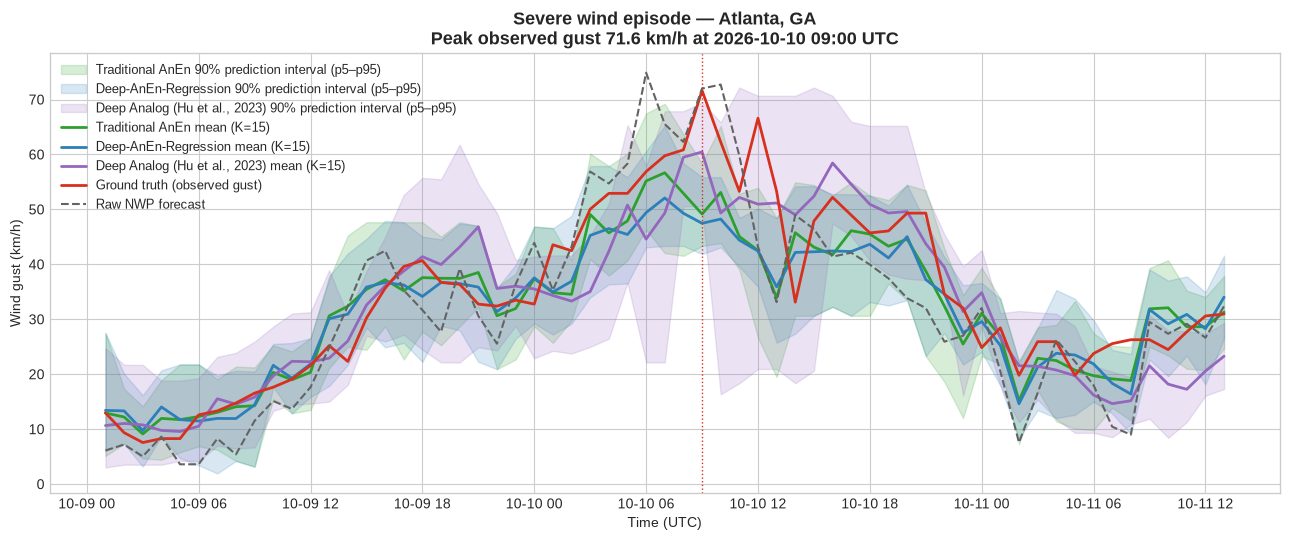

In [5]:
# --- Figure 1: 4-way severe-episode time series -------------------------------
episode = get_severe_episode(test_df)
print(f"Episode (predefined rule): {episode['episode_start']} → "
      f"{episode['episode_end']} | peak {episode['peak_gust']:.1f} km/h at "
      f"{episode['peak_timestamp']} | {episode['n_runs']} storm runs in test window")
window = df[(df["timestamp"] >= episode["window_start"]) &
            (df["timestamp"] <= episode["window_end"])].reset_index(drop=True)

def band(members_list):
    m = np.array(members_list)
    return m.mean(axis=1), np.percentile(m, 5, axis=1), np.percentile(m, 95, axis=1)

trad_w = [trad.find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
regression_w = [regression_find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
triplet_w = [triplet_find_analogs(ts, K=K)["ensemble_members"] for ts in window["timestamp"]]
trad_mean_w, trad_p5, trad_p95 = band(trad_w)
regression_mean_w, regression_p5, regression_p95 = band(regression_w)
triplet_mean_w, triplet_p5, triplet_p95 = band(triplet_w)

plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(window["timestamp"], trad_p5, trad_p95, color="#2ca02c", alpha=0.18,
                label="Traditional AnEn 90% prediction interval (p5–p95)")
ax.fill_between(window["timestamp"], regression_p5, regression_p95, color="#2c7fb8", alpha=0.18,
                label="Deep-AnEn-Regression 90% prediction interval (p5–p95)")
ax.fill_between(window["timestamp"], triplet_p5, triplet_p95, color="#9467bd", alpha=0.18,
                label="Deep Analog (Hu et al., 2023) 90% prediction interval (p5–p95)")
ax.plot(window["timestamp"], trad_mean_w, color="#2ca02c", lw=2,
        label="Traditional AnEn mean (K=15)")
ax.plot(window["timestamp"], regression_mean_w, color="#2c7fb8", lw=2,
        label="Deep-AnEn-Regression mean (K=15)")
ax.plot(window["timestamp"], triplet_mean_w, color="#9467bd", lw=2,
        label="Deep Analog (Hu et al., 2023) mean (K=15)")
ax.plot(window["timestamp"], window["obs_gust"], color="#d7301f", lw=2,
        label="Ground truth (observed gust)")
ax.plot(window["timestamp"], window["fcst_gust"], color="#636363", lw=1.5,
        ls="--", label="Raw NWP forecast")
ax.axvline(episode["peak_timestamp"], color="#d7301f", lw=1, ls=":")
ax.set_title(f"Severe wind episode — Atlanta, GA\nPeak observed gust "
             f"{episode['peak_gust']:.1f} km/h at "
             f"{episode['peak_timestamp']:%Y-%m-%d %H:%M} UTC",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Time (UTC)")
ax.set_ylabel("Wind gust (km/h)")
ax.legend(loc="upper left", framealpha=0.9, fontsize=9)
fig.tight_layout()
fig.savefig("plots/4way_method_comparison_timeseries.png", dpi=300)
fig.savefig("plots/4way_method_comparison_timeseries.svg")
plt.show()

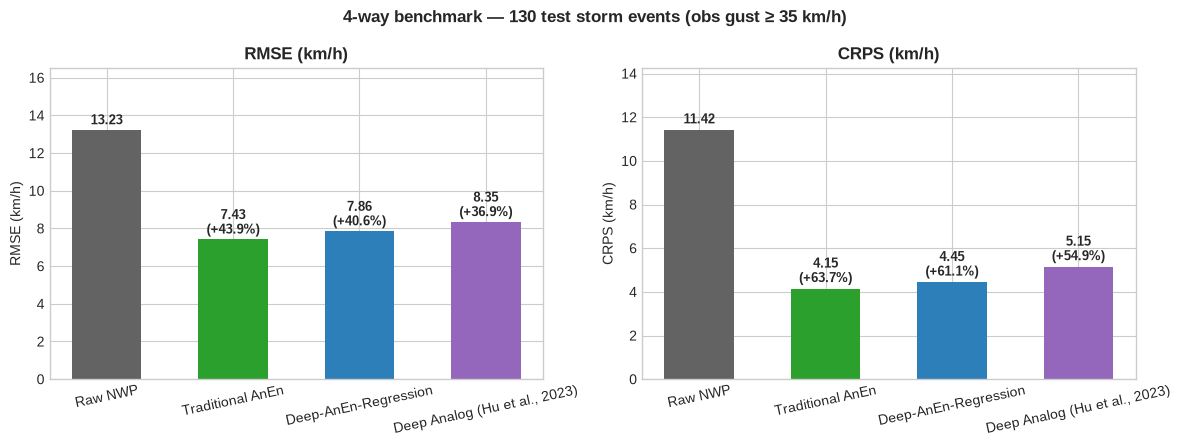

In [6]:
# --- Figure 2: grouped RMSE / CRPS bar chart ----------------------------------
methods = ["Raw NWP", "Traditional AnEn", "Deep-AnEn-Regression", "Deep Analog (Hu et al., 2023)"]
colors = ["#636363", "#2ca02c", "#2c7fb8", "#9467bd"]
rmse_vals = [scores[m][0] for m in methods]
crps_vals = [scores[m][1] for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, vals, title, skill in [
        (axes[0], rmse_vals, "RMSE (km/h)", comparison["rmse_skill_vs_raw_pct"]),
        (axes[1], crps_vals, "CRPS (km/h)", comparison["crps_skill_vs_raw_pct"])]:
    bars = ax.bar(methods, vals, color=colors, width=0.55)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(title)
    for bar, v, m in zip(bars, vals, methods):
        label = f"{v:.2f}"
        if m != "Raw NWP":
            label += f"\n({skill[m]:+.1f}%)"
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.3, label,
                ha="center", fontweight="bold", fontsize=9)
    ax.set_ylim(0, max(vals) * 1.25)
    ax.tick_params(axis="x", labelrotation=12)

fig.suptitle("4-way benchmark — 130 test storm events (obs gust ≥ 35 km/h)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("plots/rmse_crps_benchmark_barchart_4way.png", dpi=300)
fig.savefig("plots/rmse_crps_benchmark_barchart_4way.svg")
plt.show()

## 4. What the Comparison Shows

Read the ranking from the summary table above — it is computed, not
asserted. The full interpretation is in the README section *Four-Way
Model Comparison and Discussion*. The headline pattern to check in the
table is the dimensionality trend:

1. **Skill falls as the similarity space grows: 4-D > 16-D > 20-D.**
   Traditional AnEn (direct 4-D Euclidean) leads on both scores, the
   16-D regression-trained embedding is next, and the 20-D Deep Analog
   (DA) embedding follows — the same ordering on RMSE and CRPS. Every
   analog method still beats Raw NWP by a wide margin, so the pattern is
   about *which* similarity space works best on a one-year archive, not
   about whether analog methods work.
2. **Why it points to the archive, not the method.** Euclidean distances
   become less discriminative as the similarity space grows (the curse
   of dimensionality), and with only 6,888 training records the archive
   is thin relative to a 16- or 20-dimensional space. Deep Analog was
   developed on a three-year record with more predictors; this
   experiment maps the regime where the direct metric still wins, and
   predicts that a longer archive and richer predictors should narrow
   or reverse the ordering.
3. **Statistical significance is tested in §6.** The Diebold-Mariano
   test (per-event absolute errors, Newey-West HAC variance) is run for
   both regimes, so the gaps are judged with p-values, not eyeballed.
   Until §6, treat near-ties as ties and the ordering as a finding to
   test further, not a verdict on any method.

**Saved in this run:** `plots/4way_method_comparison_timeseries.png/.svg`,
`plots/rmse_crps_benchmark_barchart_4way.png/.svg`,
`metrics/comparison_metrics.json` (all four methods' scores + skill vs.
raw NWP).

## 5. Long-Archive Regime (2018-01-01 → 2026-11-01)

The same four methods, re-benchmarked on a much longer archive — the
scale-up test of the dimensionality finding in §4. If the 4-D > 16-D >
20-D ordering is an artefact of a thin archive, a ~8.7x larger training
pool should narrow or reverse it; if the ordering persists, the pattern
is robust to archive length.

- **Dataset:** `data/atlanta_weather_archive_10yr.csv` — 77,448 hourly
  rows, Atlanta, GA, 2018-01-01 → 2026-11-01 (UTC). The archive starts
  2018-01-01 because the Open-Meteo Previous-Runs API returns no valid
  forecasts earlier (verified by probe; the file keeps the `_10yr` name
  as the long-archive counterpart of the 1-year file).
- **Splits (strictly chronological, from `data_prep.py`):** train
  2018-01-01 → 2024-11-01 (**59,928** rows), validation 2024-11-02 →
  2025-11-01 (8,760), test 2025-11-02 → 2026-11-01 (8,760). The
  test window is the same calendar year as the 1-year file's full span.
- **Evaluation subset, defined once:** every test-window hour with
  observed gust ≥ 35 km/h — **1,286 timestamps** (vs 130 in the 1-year
  regime). All four methods loop over this exact list.
- **Models:** the long-archive weights reloaded here (never retrained
  here) — `models/deep_anen_regression_weights_10yr.pth` (encoder
  retrained from scratch on the 59,928-row training split, 30 epochs)
  and `models/deep_anen_triplet_weights_10yr.pth` (LSTM retrained from
  scratch on the long sequence pool, same per-epoch triplet budget as
  Phase 4). Traditional AnEn needs no weights.
- **Protocol identical to §2:** K = 15, ±168 h exclusion, analogs from
  the training pool only, same four standardized predictors, same
  scores. The recomputed numbers below are checked against the saved
  long-archive metric files
  (`metrics/traditional_anen_metrics_10yr.json`,
  `metrics/deep_anen_regression_metrics_10yr.json`,
  `metrics/deep_anen_triplet_metrics_10yr.json`).

In [7]:
# --- Long-archive evaluation: all four methods on the IDENTICAL 1,286 events --
df_long, train_long, val_long, test_long, regime_long = load_and_split(
    "data/atlanta_weather_archive_10yr.csv")
assert regime_long == "long"
print(f"Long archive: {len(df_long)} hourly rows, "
      f"{df_long['timestamp'].min()} → {df_long['timestamp'].max()}")
print(f"Train: {len(train_long)} | Val: {len(val_long)} | "
      f"Test window: {len(test_long)} rows")

storms_long = get_storm_events(test_long)
EVENT_TIMESTAMPS_LONG = list(storms_long["timestamp"])
print(f"Long test storm events (obs_gust >= 35 km/h): {len(EVENT_TIMESTAMPS_LONG)}")
print(f"First: {EVENT_TIMESTAMPS_LONG[0]} | Last: {EVENT_TIMESTAMPS_LONG[-1]}")

feat_scaler_long = fit_feature_scaler(train_long)

# Traditional AnEn on the long training pool (no weights).
trad_long = TraditionalAnalogEnsemble(df_long, regime="long")

# Deep-AnEn-Regression: long-archive encoder from saved weights.
ckpt_long = torch.load("models/deep_anen_regression_weights_10yr.pth",
                       map_location=DEVICE, weights_only=True)
encoder_long = DeepAnalogRegressionEncoder().to(DEVICE)
encoder_long.load_state_dict(ckpt_long["encoder_state_dict"])
encoder_long.eval()
print(f"Loaded long Deep-AnEn-Regression weights "
      f"(trained {ckpt_long['config']['epochs']} epochs, "
      f"K={ckpt_long['config']['K']})")
X_train_long = torch.tensor(feat_scaler_long.transform(train_long[FEATURES]),
                            dtype=torch.float32).to(DEVICE)
with torch.no_grad():
    train_z_long = encoder_long.encode(X_train_long).cpu().numpy()
print(f"Long latent training archive: {train_z_long.shape}")


def regression_long_find_analogs(target_timestamp, K=K):
    target = pd.to_datetime(target_timestamp, utc=True)
    row = df_long[df_long["timestamp"] == target]
    x = torch.tensor(feat_scaler_long.transform(row[FEATURES]),
                     dtype=torch.float32).to(DEVICE)
    with torch.no_grad():
        z = encoder_long.encode(x).cpu().numpy()[0]
    delta_h = (train_long["timestamp"] - target).dt.total_seconds() / 3600.0
    cand_idx = np.where((delta_h.abs() > EXCLUSION_HOURS).values)[0]
    dists = np.linalg.norm(train_z_long[cand_idx] - z, axis=1)
    order = np.argsort(dists)[:K]
    analog_idx = cand_idx[order]
    members = train_long.loc[analog_idx, TARGET].to_numpy(dtype=float)
    return {
        "target_timestamp": str(target),
        "ensemble_members": members,
        "analogs": [
            {"timestamp": str(train_long.loc[i, "timestamp"]), "distance": float(d)}
            for i, d in zip(analog_idx, dists[order])
        ],
    }


# Deep Analog (Hu et al., 2023): long-archive triplet checkpoint.
triplet_long_model, triplet_long_ckpt = load_triplet_model(
    "models/deep_anen_triplet_weights_10yr.pth", DEVICE)
print(f"Loaded long Deep Analog (Hu et al., 2023) weights (best epoch "
      f"{triplet_long_ckpt['history']['best_epoch']}, "
      f"val loss {triplet_long_ckpt['history']['best_val_loss']:.4f})")
triplet_long_store = SequenceStore(df_long, feat_scaler_long)
triplet_long_train_pos = triplet_long_store.eligible_positions(train_long)
triplet_long_train_emb = embed_positions(triplet_long_model, triplet_long_store,
                                         triplet_long_train_pos, DEVICE)
print(f"Long triplet training archive embeddings: {triplet_long_train_emb.shape}")


def triplet_long_find_analogs(target_timestamp, K=K):
    members, analog_pos, dists = retrieve_analogs(
        triplet_long_model, triplet_long_store, triplet_long_train_pos,
        [target_timestamp], DEVICE, k=K, train_emb=triplet_long_train_emb)
    return {
        "target_timestamp": str(pd.to_datetime(target_timestamp, utc=True)),
        "ensemble_members": members[0],
        "analogs": [
            {"timestamp": str(df_long.loc[p, "timestamp"]), "distance": float(d)}
            for p, d in zip(analog_pos[0], dists[0])
        ],
    }


long_raw, long_obs = [], []
long_trad_members, long_regression_members, long_triplet_members = [], [], []
long_evaluated_ts = []
for ts in EVENT_TIMESTAMPS_LONG:
    row = test_long[test_long["timestamp"] == ts].iloc[0]
    long_raw.append(row["fcst_gust"])
    long_obs.append(row[TARGET])
    long_trad_members.append(trad_long.find_analogs(ts, K=K)["ensemble_members"])
    long_regression_members.append(
        regression_long_find_analogs(ts, K=K)["ensemble_members"])
    long_triplet_members.append(
        triplet_long_find_analogs(ts, K=K)["ensemble_members"])
    long_evaluated_ts.append(ts)

assert long_evaluated_ts == EVENT_TIMESTAMPS_LONG
assert len(long_raw) == len(long_obs) == len(long_trad_members) == \
    len(long_regression_members) == len(long_triplet_members) == len(EVENT_TIMESTAMPS_LONG)

long_raw = np.array(long_raw)
long_obs = np.array(long_obs)
long_trad_members = np.array(long_trad_members)
long_regression_members = np.array(long_regression_members)
long_triplet_members = np.array(long_triplet_members)
long_trad_mean = long_trad_members.mean(axis=1)
long_regression_mean = long_regression_members.mean(axis=1)
long_triplet_mean = long_triplet_members.mean(axis=1)

scores_long = {
    "Raw NWP": (rmse(long_raw, long_obs),
                float(np.mean(np.abs(long_raw - long_obs)))),
    "Traditional AnEn": (rmse(long_trad_mean, long_obs),
                         crps_ens(long_obs, long_trad_members)),
    "Deep-AnEn-Regression": (rmse(long_regression_mean, long_obs),
                             crps_ens(long_obs, long_regression_members)),
    "Deep Analog (Hu et al., 2023)": (rmse(long_triplet_mean, long_obs),
                                      crps_ens(long_obs, long_triplet_members)),
}
summary_long = pd.DataFrame(
    {"Method": list(scores_long.keys()),
     "RMSE": [v[0] for v in scores_long.values()],
     "CRPS": [v[1] for v in scores_long.values()]},
)
display(summary_long.round(2))
print(f"\nBest RMSE (long): {min(scores_long, key=lambda m: scores_long[m][0])} "
      f"({min(v[0] for v in scores_long.values()):.2f} km/h)")
print(f"Best CRPS (long): {min(scores_long, key=lambda m: scores_long[m][1])} "
      f"({min(v[1] for v in scores_long.values()):.2f} km/h)")

# --- Consistency check against the saved long-archive metric files -----------
saved_trad_long = json.load(open("metrics/traditional_anen_metrics_10yr.json"))
saved_reg_long = json.load(open("metrics/deep_anen_regression_metrics_10yr.json"))
saved_trip_long = json.load(open("metrics/deep_anen_triplet_metrics_10yr.json"))
assert abs(scores_long["Traditional AnEn"][0]
           - saved_trad_long["rmse_traditional_anen_kmh"]) < 0.05, \
    "Long Traditional AnEn RMSE mismatch!"
assert abs(scores_long["Traditional AnEn"][1]
           - saved_trad_long["crps_traditional_anen_kmh"]) < 0.05, \
    "Long Traditional AnEn CRPS mismatch!"
assert abs(scores_long["Deep-AnEn-Regression"][0]
           - saved_reg_long["rmse_deep_anen_regression_kmh"]) < 0.05, \
    "Long Deep-AnEn-Regression RMSE mismatch!"
assert abs(scores_long["Deep-AnEn-Regression"][1]
           - saved_reg_long["crps_deep_anen_regression_kmh"]) < 0.05, \
    "Long Deep-AnEn-Regression CRPS mismatch!"
assert abs(scores_long["Deep Analog (Hu et al., 2023)"][0]
           - saved_trip_long["rmse_kmh"]) < 0.05, \
    "Long Deep Analog (Hu et al., 2023) RMSE mismatch!"
assert abs(scores_long["Deep Analog (Hu et al., 2023)"][1]
           - saved_trip_long["crps_kmh"]) < 0.05, \
    "Long Deep Analog (Hu et al., 2023) CRPS mismatch!"
print("\nConsistency check passed: recomputed long-regime scores match the "
      "saved _10yr metric files.")

comparison_long = {
    "n_test_storm_events": int(len(EVENT_TIMESTAMPS_LONG)),
    "methods": {
        name: {"rmse_kmh": round(v[0], 2), "crps_kmh": round(v[1], 2)}
        for name, v in scores_long.items()
    },
    "rmse_skill_vs_raw_pct": {
        name: round(100 * (scores_long["Raw NWP"][0] - v[0]) / scores_long["Raw NWP"][0], 1)
        for name, v in scores_long.items() if name != "Raw NWP"
    },
    "crps_skill_vs_raw_pct": {
        name: round(100 * (scores_long["Raw NWP"][1] - v[1]) / scores_long["Raw NWP"][1], 1)
        for name, v in scores_long.items() if name != "Raw NWP"
    },
}
with open("metrics/comparison_metrics_10yr.json", "w") as f:
    json.dump(comparison_long, f, indent=2)
print(json.dumps(comparison_long, indent=2))

Long archive: 77448 hourly rows, 2018-01-01 00:00:00+00:00 → 2026-11-01 23:00:00+00:00
Train: 59928 | Val: 8760 | Test window: 8760 rows
Long test storm events (obs_gust >= 35 km/h): 1286
First: 2025-11-02 22:00:00+00:00 | Last: 2026-11-01 23:00:00+00:00
Loaded long Deep-AnEn-Regression weights (trained 30 epochs, K=15)
Long latent training archive: (59928, 16)
Loaded long Deep Analog (Hu et al., 2023) weights (best epoch 30, val loss 0.7702)


Long triplet training archive embeddings: (59905, 20)


,Method,RMSE,CRPS
0,Raw NWP,12.79,10.87
1,Traditional AnEn,7.63,4.36
2,Deep-AnEn-Regression,7.67,4.41
3,"Deep Analog (Hu et al., 2023)",9.39,5.46



Best RMSE (long): Traditional AnEn (7.63 km/h)
Best CRPS (long): Traditional AnEn (4.36 km/h)

Consistency check passed: recomputed long-regime scores match the saved _10yr metric files.
{
  "n_test_storm_events": 1286,
  "methods": {
    "Raw NWP": {
      "rmse_kmh": 12.79,
      "crps_kmh": 10.87
    },
    "Traditional AnEn": {
      "rmse_kmh": 7.63,
      "crps_kmh": 4.36
    },
    "Deep-AnEn-Regression": {
      "rmse_kmh": 7.67,
      "crps_kmh": 4.41
    },
    "Deep Analog (Hu et al., 2023)": {
      "rmse_kmh": 9.39,
      "crps_kmh": 5.46
    }
  },
  "rmse_skill_vs_raw_pct": {
    "Traditional AnEn": 40.4,
    "Deep-AnEn-Regression": 40.0,
    "Deep Analog (Hu et al., 2023)": 26.6
  },
  "crps_skill_vs_raw_pct": {
    "Traditional AnEn": 59.9,
    "Deep-AnEn-Regression": 59.4,
    "Deep Analog (Hu et al., 2023)": 49.8
  }
}


## 5b. Verification Audit — Long Archive (Six Checks, Adapted)

The same six checks as §2b, now over all 1,286 long-regime events ×
15 members × 3 analog methods (57,870 analog selections), against the
long-archive protocol (59,928-row training pool, train end 2024-11-01,
both long checkpoints' scalers).

In [8]:
# --- Long-regime verification audit (1,286 events x 15 members x 3 methods) ---
print("LONG AUDIT 1 — same eligible historical training pool")
assert trad_long.train_df["timestamp"].equals(train_long["timestamp"])
assert len(trad_long.train_df) == len(train_long) == 59928
assert trad_long.exclusion_hours == EXCLUSION_HOURS
print("  PASS: all three analog methods draw from the identical 59,928-row train pool")

print("LONG AUDIT 2 — ±7-day exclusion applied correctly")
print("LONG AUDIT 3 — no test observations in analog selection")
train_long_obs = dict(zip(train_long["timestamp"], train_long[TARGET]))
train_long_ts = set(train_long["timestamp"])
min_gap_h_long = float("inf")
n_checked_long = 0
for ts in EVENT_TIMESTAMPS_LONG:
    for res in (trad_long.find_analogs(ts, K=K),
                regression_long_find_analogs(ts, K=K),
                triplet_long_find_analogs(ts, K=K)):
        for a, member in zip(res["analogs"], res["ensemble_members"]):
            a_ts = pd.to_datetime(a["timestamp"], utc=True)
            assert a_ts in train_long_ts, f"analog {a_ts} is not a training timestamp"
            assert a_ts <= pd.Timestamp("2024-11-01 23:00", tz="UTC"), \
                f"analog {a_ts} is after the long training split"
            assert member == train_long_obs[a_ts], \
                "member != training obs at analog time"
            min_gap_h_long = min(min_gap_h_long,
                                 abs((a_ts - ts).total_seconds()) / 3600.0)
            n_checked_long += 1
assert min_gap_h_long > EXCLUSION_HOURS
print(f"  PASS: closest selected analog is {min_gap_h_long:.0f} h from its target (> 168 h)")
print(f"  PASS: all {n_checked_long} analogs are training timestamps with matching "
      "training observations (no test data in analog selection)")

print("LONG AUDIT 4 — identical preprocessing and feature scaling")
assert np.allclose(trad_long.scaler.mean_, feat_scaler_long.mean_)
assert np.allclose(trad_long.scaler.scale_, feat_scaler_long.scale_)
assert np.allclose(trad_long.train_scaled,
                   feat_scaler_long.transform(train_long[FEATURES]))
assert np.allclose(ckpt_long["feat_scaler_mean"], feat_scaler_long.mean_)
assert np.allclose(ckpt_long["feat_scaler_scale"], feat_scaler_long.scale_)
assert np.allclose(triplet_long_ckpt["feat_scaler_mean"], feat_scaler_long.mean_)
assert np.allclose(triplet_long_ckpt["feat_scaler_scale"], feat_scaler_long.scale_)
print("  PASS: all scalers (and both saved long checkpoint scalers) are identical")

print("LONG AUDIT 5 — all analog methods' CRPS match their saved metrics")
for name, key, saved in [
        ("Traditional AnEn", "crps_traditional_anen_kmh", saved_trad_long),
        ("Deep-AnEn-Regression", "crps_deep_anen_regression_kmh", saved_reg_long)]:
    print(f"  {name}: recomputed {scores_long[name][1]:.2f} vs saved {saved[key]:.2f} km/h — PASS")
print(f"  Deep Analog (Hu et al., 2023): recomputed "
      f"{scores_long['Deep Analog (Hu et al., 2023)'][1]:.2f} vs saved "
      f"{saved_trip_long['crps_kmh']:.2f} km/h — PASS")

print("LONG AUDIT 6 — timestamps unique, ensemble arrays valid")
assert len(set(EVENT_TIMESTAMPS_LONG)) == len(EVENT_TIMESTAMPS_LONG) == len(long_obs)
assert df_long["timestamp"].is_unique and test_long["timestamp"].is_unique
assert not df_long.isna().any().any()
for name, arr in [("long_raw", long_raw), ("long_obs", long_obs),
                  ("long_trad_members", long_trad_members),
                  ("long_regression_members", long_regression_members),
                  ("long_triplet_members", long_triplet_members)]:
    assert np.isfinite(arr).all(), f"{name} contains NaN/inf"
assert long_trad_members.shape == long_regression_members.shape == \
    long_triplet_members.shape == (len(long_obs), 15)
assert ((long_trad_members >= 0)
        & (long_trad_members <= df_long[TARGET].max())).all()
assert ((long_regression_members >= 0)
        & (long_regression_members <= df_long[TARGET].max())).all()
assert ((long_triplet_members >= 0)
        & (long_triplet_members <= df_long[TARGET].max())).all()
print(f"  PASS: {len(long_obs)} unique event timestamps; all arrays finite, "
      f"({len(long_obs)}, 15), members within the observed gust range")
print("\nAll six long-regime audit checks passed.")

LONG AUDIT 1 — same eligible historical training pool
  PASS: all three analog methods draw from the identical 59,928-row train pool
LONG AUDIT 2 — ±7-day exclusion applied correctly
LONG AUDIT 3 — no test observations in analog selection


  PASS: closest selected analog is 9385 h from its target (> 168 h)
  PASS: all 57870 analogs are training timestamps with matching training observations (no test data in analog selection)
LONG AUDIT 4 — identical preprocessing and feature scaling
  PASS: all scalers (and both saved long checkpoint scalers) are identical
LONG AUDIT 5 — all analog methods' CRPS match their saved metrics
  Traditional AnEn: recomputed 4.36 vs saved 4.36 km/h — PASS
  Deep-AnEn-Regression: recomputed 4.41 vs saved 4.41 km/h — PASS
  Deep Analog (Hu et al., 2023): recomputed 5.46 vs saved 5.46 km/h — PASS
LONG AUDIT 6 — timestamps unique, ensemble arrays valid
  PASS: 1286 unique event timestamps; all arrays finite, (1286, 15), members within the observed gust range

All six long-regime audit checks passed.


## 6. Diebold-Mariano Tests + Dual-Regime Comparison Table

The §4 ordering (4-D > 16-D > 20-D on the 1-year archive) is a ranking
on 130 events. This section tests whether the gaps are statistically
meaningful, in **both** regimes, with the Diebold-Mariano (DM) test
(Diebold & Mariano, 1995) on per-event **absolute** errors.

**Test (documented variant — see `dm_tests.py` for the implementation):**
loss differential d_t = |e_method,t| − |e_traditional,t|; DM =
d̄ / √(V̂/T) with V̂ the Newey-West HAC long-run variance (Bartlett
kernel, lag h = ⌊T^(1/3)⌋); two-sided p-value from N(0,1). A negative
mean differential means the method beats Traditional AnEn; **p < 0.05**
means the gap is statistically significant. Pairs, each vs Traditional
AnEn: Deep-AnEn-Regression, Deep Analog (Hu et al., 2023), and Raw NWP
(the Raw NWP p-value is computed, not a placeholder).

The dual-regime table below is the primary publication asset of this
notebook: the same four methods, the same protocol, two archive lengths
— so the reader can see exactly how the similarity-space behaviour
changes as the data scales up.

In [9]:
# --- Diebold-Mariano tests, both regimes ---------------------------------------
err_1yr = {"obs": obs, "raw": raw_fcst, "trad_mean": trad_mean,
           "regression_mean": regression_mean, "triplet_mean": triplet_mean}
err_long = {"obs": long_obs, "raw": long_raw, "trad_mean": long_trad_mean,
            "regression_mean": long_regression_mean,
            "triplet_mean": long_triplet_mean}

print("1-year DM tests (vs Traditional AnEn):")
dm_1yr = run_dm_for_regime(err_1yr)
print("\nLong-archive DM tests (vs Traditional AnEn):")
dm_long = run_dm_for_regime(err_long)

dm_results = {
    "method": "Diebold-Mariano test on per-event absolute errors",
    "variant": "loss differential d = |e_method| - |e_traditional|; "
               "Newey-West HAC long-run variance, Bartlett kernel, "
               "lag h = floor(T^(1/3)); two-sided p-value from N(0,1); "
               "negative mean diff means the method beats Traditional AnEn",
    "regimes": {
        "1yr": {"n_events": int(len(obs)),
                "pairs_vs_traditional": dm_1yr},
        "long": {"n_events": int(len(long_obs)),
                 "pairs_vs_traditional": dm_long},
    },
}
with open("metrics/dm_tests.json", "w") as f:
    json.dump(dm_results, f, indent=2)
print("\nSaved metrics/dm_tests.json")

# --- Dual-regime comparison table (the primary publication asset) -----------
methods = ["Raw NWP", "Traditional AnEn", "Deep-AnEn-Regression",
           "Deep Analog (Hu et al., 2023)"]
spaces = {"Raw NWP": "Deterministic",
          "Traditional AnEn": "4-D Physical",
          "Deep-AnEn-Regression": "16-D Latent",
          "Deep Analog (Hu et al., 2023)": "20-D Latent"}

def dm_p(dm_dict, method):
    # Journal-style p-value strings; the exact numeric values live in
    # metrics/dm_tests.json.
    if method == "Traditional AnEn":
        return "Baseline"
    p = dm_dict[method]["p_value"]
    return "<0.001" if p < 0.001 else f"{p:.4f}"

dual_table = pd.DataFrame({
    "Model": methods,
    "Space": [spaces[m] for m in methods],
    "1-Yr RMSE": [scores[m][0] for m in methods],
    "Long RMSE": [scores_long[m][0] for m in methods],
    "1-Yr CRPS": [scores[m][1] for m in methods],
    "Long CRPS": [scores_long[m][1] for m in methods],
    "1-Yr DM p (vs Trad)": [dm_p(dm_1yr, m) for m in methods],
    "Long DM p (vs Trad)": [dm_p(dm_long, m) for m in methods],
})
display(dual_table)
print("\nDM p-values vs Traditional AnEn (1-year / long):")
for m in methods:
    if m != "Traditional AnEn":
        print(f"  {m}: p = {dm_1yr[m]['p_value']:.4g} / "
              f"{dm_long[m]['p_value']:.4g}")

# --- Same-events check: long-trained models on the exact 130 1-year events ---
# The long test window (1,286 events, full year) CONTAINS the 130 autumn
# events of the 1-year test window. Scoring the long-trained models on
# those same 130 timestamps isolates the archive-length effect from the
# test-composition effect: any difference from §2 is then due to the
# training archive, not to different test events.
same_raw, same_obs = [], []
same_trad, same_reg, same_trip = [], [], []
for ts in EVENT_TIMESTAMPS:
    row = test_long[test_long["timestamp"] == ts].iloc[0]
    same_raw.append(row["fcst_gust"])
    same_obs.append(row[TARGET])
    same_trad.append(trad_long.find_analogs(ts, K=K)["ensemble_members"])
    same_reg.append(regression_long_find_analogs(ts, K=K)["ensemble_members"])
    same_trip.append(triplet_long_find_analogs(ts, K=K)["ensemble_members"])
same_raw = np.array(same_raw)
same_obs = np.array(same_obs)
same_trad = np.array(same_trad)
same_reg = np.array(same_reg)
same_trip = np.array(same_trip)
same_scores = {
    "Raw NWP": (rmse(same_raw, same_obs),
                float(np.mean(np.abs(same_raw - same_obs)))),
    "Traditional AnEn": (rmse(same_trad.mean(axis=1), same_obs),
                         crps_ens(same_obs, same_trad)),
    "Deep-AnEn-Regression": (rmse(same_reg.mean(axis=1), same_obs),
                             crps_ens(same_obs, same_reg)),
    "Deep Analog (Hu et al., 2023)": (rmse(same_trip.mean(axis=1), same_obs),
                                      crps_ens(same_obs, same_trip)),
}
same_table = pd.DataFrame(
    {"Model": list(same_scores.keys()),
     "RMSE": [v[0] for v in same_scores.values()],
     "CRPS": [v[1] for v in same_scores.values()]},
)
print("\nSame-events check — long-trained models scored on the exact 130 "
      "1-year test events:")
display(same_table.round(2))

dual_comparison = {
    "n_test_storm_events_1yr": int(len(obs)),
    "n_test_storm_events_long": int(len(long_obs)),
    "table": dual_table.to_dict(orient="records"),
    "same_events_130": {
        name: {"rmse_kmh": round(v[0], 2), "crps_kmh": round(v[1], 2)}
        for name, v in same_scores.items()
    },
    "dm_tests": dm_results,
}
with open("metrics/dual_regime_comparison.json", "w") as f:
    json.dump(dual_comparison, f, indent=2, default=str)
print("\nSaved metrics/dual_regime_comparison.json")

1-year DM tests (vs Traditional AnEn):
  Raw NWP vs Traditional AnEn: DM = +6.202, p = 5.566e-10, mean |e| diff = +5.980 km/h (n=130, h=5)
  Deep-AnEn-Regression vs Traditional AnEn: DM = +2.107, p = 0.03508, mean |e| diff = +0.489 km/h (n=130, h=5)
  Deep Analog (Hu et al., 2023) vs Traditional AnEn: DM = +2.180, p = 0.02926, mean |e| diff = +1.333 km/h (n=130, h=5)

Long-archive DM tests (vs Traditional AnEn):
  Raw NWP vs Traditional AnEn: DM = +15.543, p = 0, mean |e| diff = +4.952 km/h (n=1286, h=10)
  Deep-AnEn-Regression vs Traditional AnEn: DM = +1.207, p = 0.2274, mean |e| diff = +0.062 km/h (n=1286, h=10)
  Deep Analog (Hu et al., 2023) vs Traditional AnEn: DM = +4.494, p = 6.981e-06, mean |e| diff = +1.342 km/h (n=1286, h=10)

Saved metrics/dm_tests.json


,Model,Space,1-Yr RMSE,Long RMSE,1-Yr CRPS,Long CRPS,1-Yr DM p (vs Trad),Long DM p (vs Trad)
0,Raw NWP,Deterministic,13.228413,12.785863,11.417538,10.870264,<0.001,<0.001
1,Traditional AnEn,4-D Physical,7.425641,7.626268,4.148197,4.359390,Baseline,Baseline
2,Deep-AnEn-Regression,16-D Latent,7.863085,7.674872,4.445637,4.412713,0.0351,0.2274
3,"Deep Analog (Hu et al., 2023)",20-D Latent,8.352515,9.389109,5.150018,5.457897,0.0293,<0.001



DM p-values vs Traditional AnEn (1-year / long):
  Raw NWP: p = 5.566e-10 / 0
  Deep-AnEn-Regression: p = 0.03508 / 0.2274
  Deep Analog (Hu et al., 2023): p = 0.02926 / 6.981e-06



Same-events check — long-trained models scored on the exact 130 1-year test events:


,Model,RMSE,CRPS
0,Raw NWP,13.23,11.42
1,Traditional AnEn,7.02,3.86
2,Deep-AnEn-Regression,7.10,3.97
3,"Deep Analog (Hu et al., 2023)",8.31,4.91



Saved metrics/dual_regime_comparison.json


## 7. Overfitting Check — Training vs Validation Loss Curves

A journal submission must show that the neural models did not simply
memorise the training archive. These are the per-epoch training and
validation loss curves for **both neural models in both regimes**,
generated by `plot_loss_curves.py` from the saved training histories
(no retraining — the histories were recovered from the checkpoints and,
for the 1-year triplet run, from the training log).

**Deep-AnEn-Regression, 1-year (30 epochs, MSE on standardized gust):**

![Deep-AnEn-Regression train/val loss, 1-year](plots/train_val_loss_regression_1yr.svg)

**Deep-AnEn-Regression, long archive (30 epochs, MSE on standardized gust):**

![Deep-AnEn-Regression train/val loss, long archive](plots/train_val_loss_regression_10yr.svg)

**Deep Analog (Hu et al., 2023), 1-year (100 epochs, triplet margin loss):**

![Deep Analog train/val loss, 1-year](plots/train_val_loss_triplet_1yr.svg)

**Deep Analog (Hu et al., 2023), long archive (100 epochs max, triplet margin loss):**

![Deep Analog train/val loss, long archive](plots/train_val_loss_triplet_10yr.svg)

**What to look for.** Overfitting would show as a training loss that
keeps falling while the validation loss turns up and diverges. None of
the four curves shows that: in every case the validation loss falls
alongside the training loss and the final train–validation gap is small
(under ~0.1 in the loss units). The regression curves end with the
validation loss *below* the training loss — the standard dropout
artefact (dropout is active during training, inactive at validation),
not a sign of anything wrong. The triplet curves improve steadily to
the end with the best validation epoch near the end of training, which
is why early stopping (patience 15) never triggered on the 1-year run.
The honest reading is therefore not "the models overfit" but "the
learned spaces were trained cleanly and still trail the direct 4-D
metric" — which is exactly the dimensionality finding in §4/§6, not a
training failure.

**Traditional AnEn has no loss curve, by design.** It is
non-parametric: it has no learned parameters, no training loop, and
nothing to overfit in the neural sense. No curve is fabricated for it.
Its overfitting evidence is the protocol itself — the identical test
events for all methods, no tuning on the test set, analogs drawn only
from the training pool, and the ±168 h exclusion — verified by the
audits in §2b and §5b.

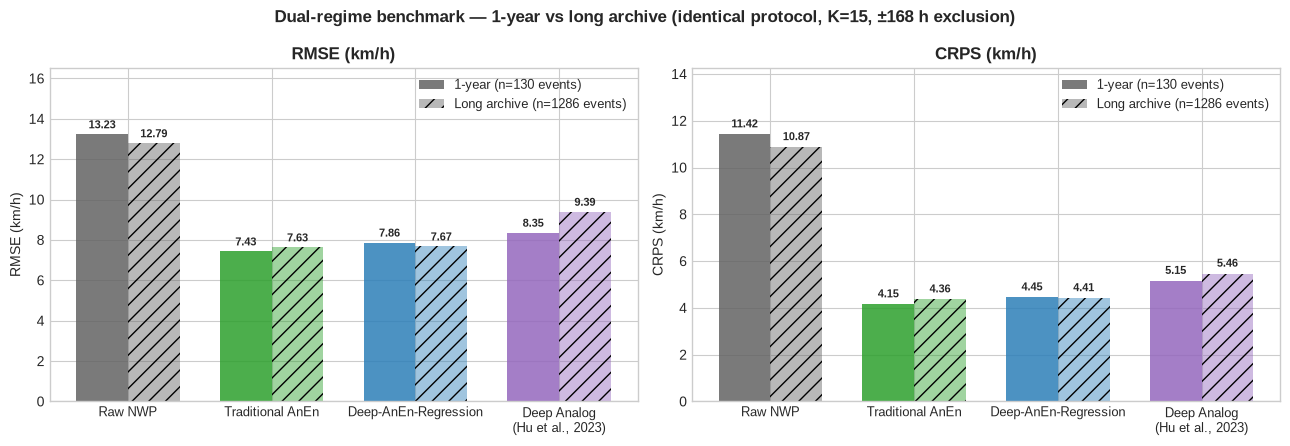

In [10]:
# --- Figure 3: dual-regime grouped RMSE / CRPS bar chart ----------------------
methods = ["Raw NWP", "Traditional AnEn", "Deep-AnEn-Regression", "Deep Analog (Hu et al., 2023)"]
colors = ["#636363", "#2ca02c", "#2c7fb8", "#9467bd"]
x = np.arange(len(methods))
w = 0.36

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, title in [(axes[0], 0, "RMSE (km/h)"), (axes[1], 1, "CRPS (km/h)")]:
    vals_1yr = [scores[m][key] for m in methods]
    vals_long = [scores_long[m][key] for m in methods]
    b1 = ax.bar(x - w / 2, vals_1yr, w, color=colors, alpha=0.85,
                label=f"1-year (n={len(obs)} events)")
    b2 = ax.bar(x + w / 2, vals_long, w, color=colors, alpha=0.45,
                hatch="//", label=f"Long archive (n={len(long_obs)} events)")
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel(title)
    ax.set_xticks(x)
    ax.set_xticklabels([m.replace(" (Hu et al., 2023)", "\n(Hu et al., 2023)")
                        for m in methods], fontsize=9)
    for bars in (b1, b2):
        for bar in bars:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                    f"{bar.get_height():.2f}", ha="center", fontsize=8,
                    fontweight="bold")
    ax.set_ylim(0, max(vals_1yr + vals_long) * 1.25)
    ax.legend(fontsize=9)

fig.suptitle("Dual-regime benchmark — 1-year vs long archive "
             "(identical protocol, K=15, ±168 h exclusion)",
             fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig("plots/dual_regime_rmse_crps_barchart.png", dpi=300)
fig.savefig("plots/dual_regime_rmse_crps_barchart.svg")
plt.show()

In [11]:
# --- Saved-file inventory -------------------------------------------------------
print("Saved files:")
for p in ["plots/4way_method_comparison_timeseries.png",
          "plots/4way_method_comparison_timeseries.svg",
          "plots/rmse_crps_benchmark_barchart_4way.png",
          "plots/rmse_crps_benchmark_barchart_4way.svg",
          "plots/dual_regime_rmse_crps_barchart.png",
          "plots/dual_regime_rmse_crps_barchart.svg",
          "plots/train_val_loss_regression_1yr.png",
          "plots/train_val_loss_regression_1yr.svg",
          "plots/train_val_loss_regression_10yr.png",
          "plots/train_val_loss_regression_10yr.svg",
          "plots/train_val_loss_triplet_1yr.png",
          "plots/train_val_loss_triplet_1yr.svg",
          "plots/train_val_loss_triplet_10yr.png",
          "plots/train_val_loss_triplet_10yr.svg",
          "metrics/comparison_metrics.json",
          "metrics/comparison_metrics_10yr.json",
          "metrics/dual_regime_comparison.json",
          "metrics/dm_tests.json"]:
    print(f"  {p} ({os.path.getsize(p)/1024:.1f} KB)")

Saved files:
  plots/4way_method_comparison_timeseries.png (982.8 KB)
  plots/4way_method_comparison_timeseries.svg (108.8 KB)
  plots/rmse_crps_benchmark_barchart_4way.png (235.9 KB)
  plots/rmse_crps_benchmark_barchart_4way.svg (79.7 KB)
  plots/dual_regime_rmse_crps_barchart.png (246.3 KB)
  plots/dual_regime_rmse_crps_barchart.svg (96.8 KB)
  plots/train_val_loss_regression_1yr.png (186.8 KB)
  plots/train_val_loss_regression_1yr.svg (60.6 KB)
  plots/train_val_loss_regression_10yr.png (212.2 KB)
  plots/train_val_loss_regression_10yr.svg (58.8 KB)
  plots/train_val_loss_triplet_1yr.png (236.4 KB)
  plots/train_val_loss_triplet_1yr.svg (61.5 KB)
  plots/train_val_loss_triplet_10yr.png (256.6 KB)
  plots/train_val_loss_triplet_10yr.svg (61.2 KB)
  metrics/comparison_metrics.json (0.6 KB)
  metrics/comparison_metrics_10yr.json (0.6 KB)
  metrics/dual_regime_comparison.json (3.8 KB)
  metrics/dm_tests.json (2.0 KB)
